In [27]:

import pandas as pd

file_path = "/content/online_retail_II.xlsx"

df = pd.read_excel(file_path)

df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [28]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()



Dataset shape: (525461, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64

In [29]:
df.columns = df.columns.str.strip()

df["Invoice"] = df["Invoice"].astype("string").str.strip()
df["Customer ID"] = pd.to_numeric(df["Customer ID"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

df = df.dropna(
    subset=["Invoice", "Customer ID", "Quantity", "Price", "InvoiceDate"]
)

df = df[
    ~df["Invoice"].str.upper().str.startswith("C", na=False)
]

df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
]

df = df.drop_duplicates().copy()

df["Customer ID"] = df["Customer ID"].astype("int64")
df["Revenue"] = df["Quantity"] * df["Price"]

print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["Customer ID"].nunique())

display(df.head())
df_clean = df.copy()

Cleaned dataset shape: (400916, 9)
Unique customers: 4312


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [30]:

orders = (
    df_clean.groupby(
        ["Customer ID", "Invoice"], as_index=False
    )
    .agg(
        OrderDate=("InvoiceDate", "min"),
        OrderValue=("Revenue", "sum"),
        TotalItems=("Quantity", "sum")
    )
)

print("Total unique orders:", orders["Invoice"].nunique())
print("Total customers:", orders["Customer ID"].nunique())

display(orders.head())


Total unique orders: 19213
Total customers: 4312


,Customer ID,Invoice,OrderDate,OrderValue,TotalItems
0,12346,491725,2009-12-14 08:34:00,45.0,10
1,12346,491742,2009-12-14 11:00:00,22.5,5
2,12346,491744,2009-12-14 11:02:00,22.5,5
3,12346,492718,2009-12-18 10:47:00,22.5,5
4,12346,492722,2009-12-18 10:55:00,1.0,1


In [31]:
# Count unique invoices for each customer

customer_summary = (
    orders.groupby("Customer ID")
    .agg(
        TotalPurchases=("Invoice", "nunique"),
        TotalRevenue=("OrderValue", "sum")
    )
    .reset_index()
)

customer_summary["TotalRevenue"] = (
    customer_summary["TotalRevenue"].round(2)
)

customer_summary.head()

,Customer ID,TotalPurchases,TotalRevenue
0,12346,11,372.86
1,12347,2,1323.32
2,12348,1,222.16
3,12349,3,2671.14
4,12351,1,300.93


In [32]:
# Identify first-time and repeat customers

customer_summary["CustomerType"] = customer_summary[
    "TotalPurchases"
].apply(
    lambda x: "First-time" if x == 1 else "Repeat"
)

print("Customer classification completed!")
display(customer_summary.head(10))

print("\nCustomer types:")
display(
    customer_summary["CustomerType"].value_counts()
)

Customer classification completed!


,Customer ID,TotalPurchases,TotalRevenue,CustomerType
0,12346,11,372.86,Repeat
1,12347,2,1323.32,Repeat
2,12348,1,222.16,First-time
3,12349,3,2671.14,Repeat
4,12351,1,300.93,First-time
5,12352,2,343.80,Repeat
6,12353,1,317.76,First-time
7,12355,1,488.21,First-time
8,12356,3,3560.30,Repeat
9,12357,2,12079.99,Repeat



Customer types:


,count
CustomerType,
Repeat,2893
First-time,1419


In [33]:
total_customers = customer_summary["Customer ID"].nunique()

repeat_customers = (
    customer_summary["CustomerType"] == "Repeat"
).sum()

first_time_customers = (
    customer_summary["CustomerType"] == "First-time"
).sum()

repeat_purchase_rate = (
    repeat_customers / total_customers * 100
    if total_customers > 0 else 0
)

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("First-time Customers:", first_time_customers)
print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%")

Total Customers: 4312
Repeat Customers: 2893
First-time Customers: 1419
Repeat Purchase Rate: 67.09%


In [34]:
# Join customer segments with invoice-level orders

comparison_data = orders.merge(
    customer_summary[["Customer ID", "CustomerType"]],
    on="Customer ID",
    how="left"
)

segment_comparison = (
    comparison_data.groupby("CustomerType")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        TotalOrders=("Invoice", "nunique"),
        TotalRevenue=("OrderValue", "sum"),
        AverageOrderValue=("OrderValue", "mean")
    )
    .reset_index()
)

segment_comparison["TotalRevenue"] = (
    segment_comparison["TotalRevenue"].round(2)
)

segment_comparison["AverageOrderValue"] = (
    segment_comparison["AverageOrderValue"].round(2)
)

display(segment_comparison)

,CustomerType,CustomerCount,TotalOrders,TotalRevenue,AverageOrderValue
0,First-time,1419,1419,496304.47,349.76
1,Repeat,2893,17794,8301929.27,466.56


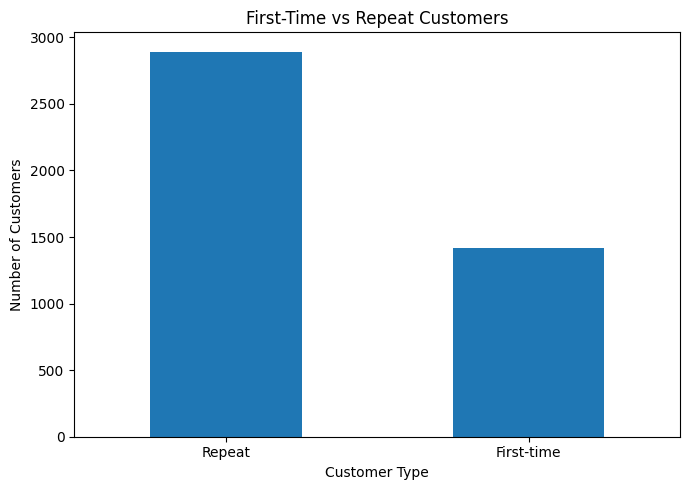

In [35]:
import matplotlib.pyplot as plt

customer_counts = customer_summary["CustomerType"].value_counts()

customer_counts.plot(kind="bar", figsize=(7, 5))

plt.title("First-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

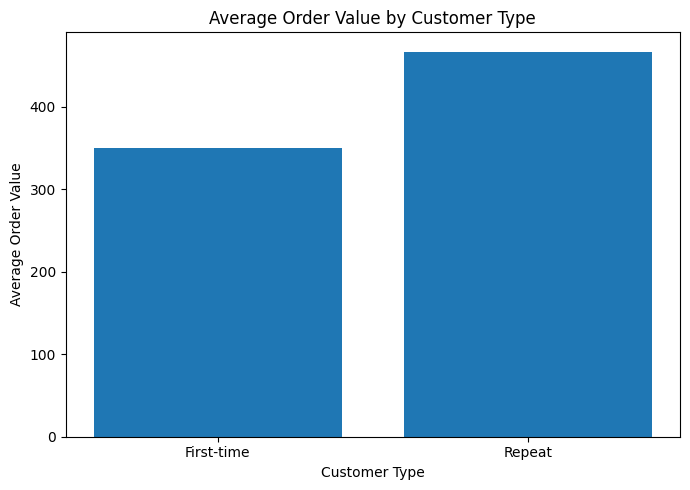

In [36]:
plt.figure(figsize=(7, 5))

plt.bar(
    segment_comparison["CustomerType"],
    segment_comparison["AverageOrderValue"]
)

plt.title("Average Order Value by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Order Value")
plt.tight_layout()
plt.show()

In [37]:
# Identify customers who purchase in a later calendar month

monthly_customers = orders[
    ["Customer ID", "OrderDate"]
].drop_duplicates().copy()

monthly_customers["Month"] = (
    monthly_customers["OrderDate"].dt.to_period("M")
)

monthly_customers = monthly_customers.drop_duplicates(
    subset=["Customer ID", "Month"]
)

first_month = (
    monthly_customers.groupby("Customer ID")["Month"]
    .min()
    .rename("FirstPurchaseMonth")
)

monthly_customers = monthly_customers.join(
    first_month, on="Customer ID"
)

monthly_trends = (
    monthly_customers.groupby("Month")
    .agg(
        ActiveCustomers=("Customer ID", "nunique")
    )
    .reset_index()
)

returning = (
    monthly_customers[
        monthly_customers["Month"] >
        monthly_customers["FirstPurchaseMonth"]
    ]
    .groupby("Month")["Customer ID"]
    .nunique()
)

monthly_trends["ReturningCustomers"] = (
    monthly_trends["Month"].map(returning).fillna(0).astype(int)
)

monthly_trends["ReturningCustomerRate"] = (
    monthly_trends["ReturningCustomers"]
    / monthly_trends["ActiveCustomers"] * 100
).round(2)

monthly_trends["Month"] = monthly_trends["Month"].astype(str)

display(monthly_trends)

,Month,ActiveCustomers,ReturningCustomers,ReturningCustomerRate
0,2009-12,955,0,0.00
1,2010-01,720,337,46.81
2,2010-02,772,398,51.55
3,2010-03,1057,614,58.09
4,2010-04,942,648,68.79
5,2010-05,966,712,73.71
6,2010-06,1041,771,74.06
7,2010-07,928,742,79.96
8,2010-08,911,749,82.22
9,2010-09,1145,902,78.78


Business Insights and Recommendations

Key Findings

1. Repeat Purchase Rate: 67.09% of customers made more than one purchase during the analysis period.
2. Customer Segmentation: Out of 4,312 customers, 2,893 were repeat customers and 1,419 were first-time customers.
3. Customer Loyalty: Repeat customers represent a substantial share of the customer base.
4. Average Order Value: Compare the AOV of first-time and repeat customers to understand differences in spending behavior.

Recommendations

- Encourage first-time customers to make another purchase through follow-up offers.
- Introduce loyalty rewards for repeat customers.
- Monitor repeat purchase rates regularly to track customer retention.
- Analyze customer purchasing patterns to identify opportunities to increase revenue.